
# Enterprise RAG Intelligent Knowledge Assistant

**Author:** Balaji  
**Environment:** Google Colab  
**Architecture:** Gemini 2.5 Flash + Sentence Transformers + Qdrant (local in-memory) + BM25 hybrid retrieval + LangGraph

This notebook ingests enterprise documents, extracts and chunks text, creates dense embeddings, indexes chunks in Qdrant, combines semantic and lexical retrieval using reciprocal-rank fusion, and answers questions with source citations. It includes a small reproducible demo corpus, retrieval evaluation, and exportable reports.

> For privacy and portability, Qdrant runs locally in the Colab runtime. No Google Drive connection is used. Uploaded documents and the in-memory index disappear when the runtime is reset unless you export the reports. Do not upload confidential documents to a public notebook.

## 1. Install compatible dependencies

Run this cell once in a fresh Colab runtime. Restart the runtime if Colab requests it, then continue from the imports cell.

In [1]:
%pip -q install -U \
  "numpy<2.3" "pandas<3" \
  "sentence-transformers>=3.3,<6" \
  "qdrant-client>=1.12,<2" "rank-bm25>=0.2.2,<0.3" \
  "langchain-core>=0.3,<2" "langchain-google-genai>=2.1,<5" \
  "langgraph>=0.2,<2" "pymupdf>=1.24" "python-docx>=1.1" \
  "scikit-learn>=1.5" "matplotlib>=3.8"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.6.1 which is incompatible.


## 2. Imports and configuration

In [2]:
import os, re, json, time, uuid, math, warnings
from pathlib import Path
from typing import TypedDict, List, Dict, Any
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sentence_transformers import SentenceTransformer
from qdrant_client import QdrantClient, models
from rank_bm25 import BM25Okapi
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import StateGraph, START, END

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
PROJECT_NAME = "Enterprise RAG Intelligent Knowledge Assistant"
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
LLM_MODEL = "gemini-2.5-flash"
COLLECTION_NAME = "enterprise_knowledge"
TOP_K_DENSE = 8
TOP_K_BM25 = 8
TOP_K_FINAL = 5
CHUNK_SIZE = 900
CHUNK_OVERLAP = 150
print(f"{PROJECT_NAME} | embedding={EMBEDDING_MODEL} | LLM={LLM_MODEL}")

Enterprise RAG Intelligent Knowledge Assistant | embedding=sentence-transformers/all-MiniLM-L6-v2 | LLM=gemini-2.5-flash


## 3. Configure Gemini securely

The API key is requested at runtime and is not written into notebook source or output. Retrieval and evaluation can still run without a key; generation will then return a transparent extractive fallback. Create a key in Google AI Studio if you want Gemini answers.

In [3]:
from getpass import getpass
try:
    from google.colab import userdata
    GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
except Exception:
    GEMINI_API_KEY = None
if not GEMINI_API_KEY:
    entered = getpass("Gemini API key (press Enter to skip live generation): ")
    GEMINI_API_KEY = entered.strip() or None

llm = None
if GEMINI_API_KEY:
    llm = ChatGoogleGenerativeAI(
        model=LLM_MODEL,
        google_api_key=GEMINI_API_KEY,
        temperature=0.1,
        max_retries=2,
        timeout=60,
    )
    print("Gemini client configured. The first request will verify connectivity and quota.")
else:
    print("No API key supplied. Retrieval tests will run; answer generation will use the extractive fallback.")

Gemini API key (press Enter to skip live generation): ··········
No API key supplied. Retrieval tests will run; answer generation will use the extractive fallback.


## 4. Load enterprise documents

Supported formats: PDF, DOCX, TXT and Markdown. Upload your own documents in Colab. If you skip upload, a clearly labelled sample policy corpus is used so the complete retrieval pipeline can be demonstrated.

In [4]:
from google.colab import files

uploaded = files.upload()

SAMPLE_DOCS = {
    "sample_leave_policy.txt": """LEAVE POLICY
Employees receive 18 days of paid annual leave per calendar year. Leave requests should be submitted in the HR portal at least five working days before the planned leave. Managers approve requests based on team coverage. Sick leave of up to 6 days is available annually; a medical certificate may be requested for absences longer than two consecutive working days. Unused annual leave may be carried forward up to 5 days, subject to local law and HR approval.""",
    "sample_security_policy.txt": """INFORMATION SECURITY POLICY
Employees must use multi-factor authentication (MFA) for all company systems. Passwords must be at least 14 characters and must not be reused across company and personal accounts. Suspected phishing messages or lost devices must be reported to the Security Operations team immediately through the incident portal. Company data classified as confidential must be stored only in approved company-managed systems. Access is granted using least-privilege principles and reviewed quarterly.""",
    "sample_expense_policy.txt": """TRAVEL AND EXPENSE POLICY
Air travel must be booked in economy class unless a vice president approves an exception in writing. Hotel expenses are reimbursable up to the city-specific nightly cap published by Finance. Employees must submit expense claims with itemized receipts within 30 calendar days after the trip. Meals are reimbursed up to the daily limit for the destination; alcohol is not reimbursable. Expenses above the policy limit require prior written manager approval.""",
}

def extract_file_text(file_path: str) -> str:
    path = Path(file_path)
    suffix = path.suffix.lower()
    if suffix == ".pdf":
        import fitz
        with fitz.open(path) as pdf:
            return "\n".join(page.get_text("text") for page in pdf)
    if suffix == ".docx":
        from docx import Document
        doc = Document(path)
        return "\n".join(p.text for p in doc.paragraphs if p.text.strip())
    if suffix in {".txt", ".md"}:
        return path.read_text(encoding="utf-8", errors="ignore")
    raise ValueError(f"Unsupported file type: {suffix}")

raw_documents = []
if uploaded:
    for filename, content in uploaded.items():
        local_path = Path(filename)
        # Colab's upload dictionary gives bytes; persist temporarily for PDF/DOCX parsers.
        local_path.write_bytes(content)
        try:
            text = extract_file_text(str(local_path))
            if text.strip():
                raw_documents.append({"source": local_path.name, "text": text})
        except Exception as exc:
            print(f"Skipped {filename}: {exc}")
else:
    raw_documents = [{"source": name, "text": text} for name, text in SAMPLE_DOCS.items()]
    print("Using demonstration policies. Upload your own documents to replace these samples.")

if not raw_documents:
    raise ValueError("No readable documents found. Upload at least one PDF, DOCX, TXT or MD file.")
print(f"Loaded {len(raw_documents)} document(s).")
for item in raw_documents:
    print(f"- {item['source']}: {len(item['text']):,} characters")

Using demonstration policies. Upload your own documents to replace these samples.
Loaded 3 document(s).
- sample_leave_policy.txt: 472 characters
- sample_security_policy.txt: 513 characters
- sample_expense_policy.txt: 481 characters


## 5. Clean text and create overlapping chunks

In [5]:
def clean_text(text: str) -> str:
    text = text.replace("\x00", " ")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

def chunk_text(text: str, chunk_size: int = CHUNK_SIZE, overlap: int = CHUNK_OVERLAP) -> List[str]:
    text = clean_text(text)
    if not text:
        return []
    if overlap >= chunk_size:
        raise ValueError("CHUNK_OVERLAP must be smaller than CHUNK_SIZE")
    chunks, start = [], 0
    while start < len(text):
        end = min(start + chunk_size, len(text))
        if end < len(text):
            boundary = max(text.rfind("\n", start, end), text.rfind(". ", start, end))
            if boundary > start + int(chunk_size * 0.55):
                end = boundary + 1
        piece = text[start:end].strip()
        if piece:
            chunks.append(piece)
        if end >= len(text):
            break
        start = max(end - overlap, start + 1)
    return chunks

chunks = []
for doc in raw_documents:
    for index, chunk in enumerate(chunk_text(doc["text"])):
        chunks.append({
            "id": str(uuid.uuid4()),
            "source": doc["source"],
            "chunk_index": index,
            "text": chunk,
        })
if not chunks:
    raise ValueError("Document parsing produced no text chunks.")
chunk_df = pd.DataFrame(chunks)
print(f"Created {len(chunks)} chunks | mean chars={chunk_df.text.str.len().mean():.0f}")
display(chunk_df[["source", "chunk_index", "text"]].head(8))

Created 3 chunks | mean chars=489


,source,chunk_index,text
0,sample_leave_policy.txt,0,LEAVE POLICY\nEmployees receive 18 days of pai...
1,sample_security_policy.txt,0,INFORMATION SECURITY POLICY\nEmployees must us...
2,sample_expense_policy.txt,0,TRAVEL AND EXPENSE POLICY\nAir travel must be ...


## 6. Generate embeddings and create the Qdrant vector index

The Qdrant collection is local and in-memory; it requires no Qdrant Cloud credentials. Sentence Transformers downloads the embedding model on first use in Colab.

In [6]:
embedding_model = SentenceTransformer(EMBEDDING_MODEL)
texts = [item["text"] for item in chunks]
embeddings = embedding_model.encode(
    texts, batch_size=32, show_progress_bar=True,
    convert_to_numpy=True, normalize_embeddings=True
).astype("float32")
vector_size = int(embeddings.shape[1])

qdrant = QdrantClient(":memory:")
qdrant.create_collection(
    collection_name=COLLECTION_NAME,
    vectors_config=models.VectorParams(size=vector_size, distance=models.Distance.COSINE),
)
points = []
for item, vector in zip(chunks, embeddings):
    payload = {k: item[k] for k in ("source", "chunk_index", "text")}
    points.append(models.PointStruct(id=item["id"], vector=vector.tolist(), payload=payload))
qdrant.upsert(collection_name=COLLECTION_NAME, points=points, wait=True)
print(f"Indexed {len(points)} chunks in Qdrant collection '{COLLECTION_NAME}' ({vector_size}-dim vectors).")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Indexed 3 chunks in Qdrant collection 'enterprise_knowledge' (384-dim vectors).


## 7. Hybrid retrieval: dense Qdrant + BM25 + reciprocal-rank fusion

In [7]:
def tokenize(text: str) -> List[str]:
    return re.findall(r"[a-z0-9]+", text.lower())

bm25_corpus = [tokenize(item["text"]) for item in chunks]
bm25 = BM25Okapi(bm25_corpus)
chunk_by_id = {item["id"]: item for item in chunks}

def dense_search(query: str, limit: int = TOP_K_DENSE):
    qvec = embedding_model.encode([query], convert_to_numpy=True, normalize_embeddings=True)[0]
    hits = qdrant.query_points(
        collection_name=COLLECTION_NAME,
        query=qvec.tolist(),
        limit=min(limit, len(chunks)),
        with_payload=True,
    ).points
    return [{"id": str(hit.id), "score": float(hit.score), **hit.payload} for hit in hits]

def lexical_search(query: str, limit: int = TOP_K_BM25):
    scores = bm25.get_scores(tokenize(query))
    order = np.argsort(scores)[::-1][:min(limit, len(chunks))]
    return [{"id": chunks[i]["id"], "score": float(scores[i]), **chunks[i]} for i in order if scores[i] > 0]

def hybrid_search(query: str, top_k: int = TOP_K_FINAL, rrf_k: int = 60):
    dense = dense_search(query)
    lexical = lexical_search(query)
    fused = {}
    for ranked in (dense, lexical):
        for rank, item in enumerate(ranked, start=1):
            key = item["id"]
            if key not in fused:
                fused[key] = {**item, "rrf_score": 0.0, "dense_rank": None, "bm25_rank": None}
            fused[key]["rrf_score"] += 1.0 / (rrf_k + rank)
            if ranked is dense:
                fused[key]["dense_rank"] = rank
            else:
                fused[key]["bm25_rank"] = rank
    return sorted(fused.values(), key=lambda x: x["rrf_score"], reverse=True)[:top_k]

# Retrieval smoke test
smoke_query = "How many days of annual leave can employees carry forward?"
smoke_hits = hybrid_search(smoke_query)
assert smoke_hits, "Hybrid retrieval returned no results."
assert any("leave" in h["source"].lower() for h in smoke_hits), "Expected leave policy was not retrieved."
print("Hybrid retrieval smoke test: PASS")
for rank, hit in enumerate(smoke_hits, 1):
    print(f"{rank}. {hit['source']} | RRF={hit['rrf_score']:.4f} | {hit['text'][:180]}...")

Hybrid retrieval smoke test: PASS
1. sample_leave_policy.txt | RRF=0.0328 | LEAVE POLICY
Employees receive 18 days of paid annual leave per calendar year. Leave requests should be submitted in the HR portal at least five working days before the planned lea...
2. sample_expense_policy.txt | RRF=0.0323 | TRAVEL AND EXPENSE POLICY
Air travel must be booked in economy class unless a vice president approves an exception in writing. Hotel expenses are reimbursable up to the city-specif...
3. sample_security_policy.txt | RRF=0.0317 | INFORMATION SECURITY POLICY
Employees must use multi-factor authentication (MFA) for all company systems. Passwords must be at least 14 characters and must not be reused across com...


## 8. LangGraph RAG workflow with grounded citations

The graph has two nodes: retrieve relevant chunks, then generate an answer. Gemini is used when configured. If no key is provided, the fallback returns retrieved excerpts rather than inventing an answer.

In [8]:
class RAGState(TypedDict, total=False):
    question: str
    retrieved: List[Dict[str, Any]]
    answer: str
    sources: List[str]
    mode: str

def retrieve_node(state: RAGState) -> Dict[str, Any]:
    results = hybrid_search(state["question"], top_k=TOP_K_FINAL)
    return {"retrieved": results, "sources": sorted(set(x["source"] for x in results))}

def generate_node(state: RAGState) -> Dict[str, Any]:
    results = state.get("retrieved", [])
    if not results:
        return {"answer": "I could not find relevant information in the indexed documents.", "mode": "no_context"}
    context = "\n\n".join(
        f"[Source: {x['source']} | Chunk: {x['chunk_index']}]\n{x['text']}" for x in results
    )
    if llm is None:
        excerpts = "\n\n".join(
            f"- **{x['source']}**: {x['text'][:500]}" for x in results[:3]
        )
        return {"answer": "Gemini is not configured, so here are the most relevant retrieved excerpts.\n\n" + excerpts,
                "mode": "extractive_fallback"}
    prompt = (
        "Answer the user's question using ONLY the supplied enterprise context. "
        "If the context does not contain the answer, say so. Do not infer policy details. "
        "Cite every factual statement using [Source: filename]. Keep the answer concise.\n\n"
        f"CONTEXT:\n{context}\n\nQUESTION: {state['question']}"
    )
    response = llm.invoke([
        SystemMessage(content="You are a careful enterprise knowledge assistant. Ground answers in provided sources."),
        HumanMessage(content=prompt),
    ])
    return {"answer": str(response.content), "mode": "gemini"}

graph_builder = StateGraph(RAGState)
graph_builder.add_node("retrieve", retrieve_node)
graph_builder.add_node("generate", generate_node)
graph_builder.add_edge(START, "retrieve")
graph_builder.add_edge("retrieve", "generate")
graph_builder.add_edge("generate", END)
rag_app = graph_builder.compile()

def ask(question: str) -> Dict[str, Any]:
    if not question or not question.strip():
        raise ValueError("Please enter a question.")
    result = rag_app.invoke({"question": question.strip()})
    return result

print("LangGraph workflow compiled successfully.")

LangGraph workflow compiled successfully.


## 9. Ask questions

Change the question below to query your own uploaded policies and knowledge documents.

In [9]:
question = "How many days of annual leave can be carried forward, and how early should employees request leave?"
result = ask(question)
display(Markdown(f"### Question\n{question}\n\n### Answer\n{result['answer']}"))
print("Generation mode:", result.get("mode"))
print("Retrieved sources:", result.get("sources", []))

### Question
How many days of annual leave can be carried forward, and how early should employees request leave?

### Answer
Gemini is not configured, so here are the most relevant retrieved excerpts.

- **sample_leave_policy.txt**: LEAVE POLICY
Employees receive 18 days of paid annual leave per calendar year. Leave requests should be submitted in the HR portal at least five working days before the planned leave. Managers approve requests based on team coverage. Sick leave of up to 6 days is available annually; a medical certificate may be requested for absences longer than two consecutive working days. Unused annual leave may be carried forward up to 5 days, subject to local law and HR approval.

- **sample_expense_policy.txt**: TRAVEL AND EXPENSE POLICY
Air travel must be booked in economy class unless a vice president approves an exception in writing. Hotel expenses are reimbursable up to the city-specific nightly cap published by Finance. Employees must submit expense claims with itemized receipts within 30 calendar days after the trip. Meals are reimbursed up to the daily limit for the destination; alcohol is not reimbursable. Expenses above the policy limit require prior written manager approval.

- **sample_security_policy.txt**: INFORMATION SECURITY POLICY
Employees must use multi-factor authentication (MFA) for all company systems. Passwords must be at least 14 characters and must not be reused across company and personal accounts. Suspected phishing messages or lost devices must be reported to the Security Operations team immediately through the incident portal. Company data classified as confidential must be stored only in approved company-managed systems. Access is granted using least-privilege principles and review

Generation mode: extractive_fallback
Retrieved sources: ['sample_expense_policy.txt', 'sample_leave_policy.txt', 'sample_security_policy.txt']


## 10. Retrieval evaluation

This reproducible evaluation uses three queries aligned with the included demonstration policies. For uploaded private documents, edit `evaluation_cases` so each `expected_source` matches a real filename. Precision@k measures the fraction of returned chunks from the expected source; Recall@k is 1 when at least one expected-source chunk appears in the top-k results. These are retrieval metrics, not a claim of answer correctness.

In [10]:
evaluation_cases = [
    {"question": "What is the annual paid leave allowance and carry-forward limit?", "expected_source": "sample_leave_policy.txt"},
    {"question": "What are the password length and MFA requirements?", "expected_source": "sample_security_policy.txt"},
    {"question": "How long do employees have to submit expense claims?", "expected_source": "sample_expense_policy.txt"},
]

def evaluate_retrieval(cases, k=TOP_K_FINAL):
    rows = []
    for case in cases:
        hits = hybrid_search(case["question"], top_k=k)
        relevant = [h for h in hits if h["source"] == case["expected_source"]]
        precision = len(relevant) / k
        recall = 1.0 if relevant else 0.0
        rows.append({
            "question": case["question"],
            "expected_source": case["expected_source"],
            "retrieved_sources": ";".join(sorted(set(h["source"] for h in hits))),
            "precision_at_k": precision,
            "recall_at_k": recall,
            "hit_at_k": int(bool(relevant)),
        })
    return pd.DataFrame(rows)

evaluation_df = evaluate_retrieval(evaluation_cases)
display(evaluation_df)
summary_metrics = {
    "queries": int(len(evaluation_df)),
    "mean_precision_at_k": float(evaluation_df["precision_at_k"].mean()),
    "mean_recall_at_k": float(evaluation_df["recall_at_k"].mean()),
    "hit_rate_at_k": float(evaluation_df["hit_at_k"].mean()),
    "k": TOP_K_FINAL,
}
print(json.dumps(summary_metrics, indent=2))

,question,expected_source,retrieved_sources,precision_at_k,recall_at_k,hit_at_k
0,What is the annual paid leave allowance and ca...,sample_leave_policy.txt,sample_expense_policy.txt;sample_leave_policy....,0.2,1.0,1
1,What are the password length and MFA requireme...,sample_security_policy.txt,sample_expense_policy.txt;sample_leave_policy....,0.2,1.0,1
2,How long do employees have to submit expense c...,sample_expense_policy.txt,sample_expense_policy.txt;sample_leave_policy....,0.2,1.0,1


{
  "queries": 3,
  "mean_precision_at_k": 0.20000000000000004,
  "mean_recall_at_k": 1.0,
  "hit_rate_at_k": 1.0,
  "k": 5
}


## 11. Inspect retrieved evidence and visualize evaluation

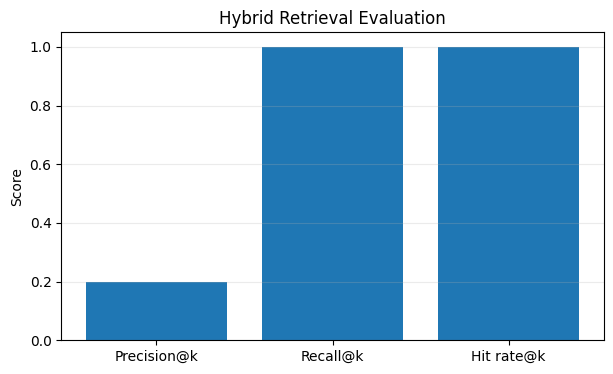

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["Precision@k", "Recall@k", "Hit rate@k"], [
    summary_metrics["mean_precision_at_k"],
    summary_metrics["mean_recall_at_k"],
    summary_metrics["hit_rate_at_k"],
])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Hybrid Retrieval Evaluation")
ax.grid(axis="y", alpha=0.25)
plt.show()

## 12. Export evaluation results and run metadata

The export folder can be downloaded from Colab. The Qdrant index is in-memory and is not exported by this notebook; rerun ingestion to rebuild it.

In [12]:
OUTPUT_DIR = Path("rag_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
evaluation_df.to_csv(OUTPUT_DIR / "retrieval_evaluation.csv", index=False)
with open(OUTPUT_DIR / "summary_metrics.json", "w", encoding="utf-8") as f:
    json.dump(summary_metrics, f, indent=2)
run_metadata = {
    "project": PROJECT_NAME,
    "embedding_model": EMBEDDING_MODEL,
    "llm_model": LLM_MODEL,
    "generation_mode": "gemini" if llm is not None else "extractive_fallback",
    "document_count": len(raw_documents),
    "chunk_count": len(chunks),
    "vector_dimension": vector_size,
    "collection": COLLECTION_NAME,
    "top_k": TOP_K_FINAL,
    "timestamp_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
}
with open(OUTPUT_DIR / "run_metadata.json", "w", encoding="utf-8") as f:
    json.dump(run_metadata, f, indent=2)
print("Exported:", [p.name for p in OUTPUT_DIR.iterdir()])

Exported: ['retrieval_evaluation.csv', 'run_metadata.json', 'summary_metrics.json']


## 13. Interactive question loop (optional)

Run this cell to ask multiple questions during the current Colab session. Stop the loop with `exit`.

In [13]:
while True:
    user_question = input("\nAsk the knowledge assistant (or type 'exit'): ").strip()
    if user_question.lower() in {"exit", "quit", "q"}:
        print("Session ended.")
        break
    try:
        response = ask(user_question)
        print("\nANSWER\n", response["answer"])
        print("\nSOURCES:", ", ".join(response.get("sources", [])))
        print("MODE:", response.get("mode"))
    except Exception as exc:
        print(f"Request failed: {type(exc).__name__}: {exc}")


Ask the knowledge assistant (or type 'exit'): exit
Session ended.


## 14. Limitations and responsible use

- Gemini calls require a valid API key, network access, and available quota. This notebook does not contain a hard-coded secret.
- The embedding model is downloaded from Hugging Face at runtime; first run may take several minutes.
- Qdrant uses local in-memory storage. Restarting the Colab runtime clears the collection; rerun ingestion to rebuild it.
- Retrieval metrics evaluate source matching on a small test set. They do not establish factual correctness, fairness, security, or production readiness.
- PDF extraction quality depends on document structure. Scanned PDFs need OCR, which is not included here.
- Before production use, add access control, tenant isolation, PII handling, document-level permissions, audit logging, prompt-injection defenses, monitoring, and a larger human-reviewed evaluation set.

**Author:** Balaji